# RT-DETRv2-S

Дообучение `PekingU/rtdetr_v2_r18vd` на один класс `kleimo`. Параметры лежат в словаре `params` и уходят в ClearML через `task.connect`, как в ноутбуке YOLO.

Ноутбук локальный. Картинки лежат рядом с репозиторием: `stamps_coco_merged`, негативы в `Клеймы /ornaments_without_copies` и `Клеймы /empty`. Веса пишутся в `runs/rtdetr_v2_s`.

In [5]:
!pip install -q clearml transformers

In [ ]:
import os

os.environ["CLEARML_NO_DEFAULT_CONFIG"] = "1"
os.environ["CLEARML_WEB_HOST"] = "https://app.clear.ml"
os.environ["CLEARML_API_HOST"] = "https://api.clear.ml"
os.environ["CLEARML_FILES_HOST"] = "https://files.clear.ml"
os.environ["CLEARML_API_ACCESS_KEY"] = ""
os.environ["CLEARML_API_SECRET_KEY"] = ""

from clearml import Task

ClearML Task: created new task id=5c6d54975d6f4d56a2967a735609d52b
ClearML results page: https://app.clear.ml/projects/f87f0b4359f2400b897396affc7b92c5/tasks/5c6d54975d6f4d56a2967a735609d52b/output/log
2026-10-24 13:45:35,500 - clearml.resource_monitor - WARNING - Could not fetch GPU stats: NVML Shared Library Not Found
train 244 test 61 всего 305
mps
ClearML Monitor: GPU monitoring failed getting GPU reading, switching off GPU monitoring


Loading weights:   0%|          | 0/529 [00:00<?, ?it/s]

[transformers] RTDetrV2ForObjectDetection LOAD REPORT from: PekingU/rtdetr_v2_r18vd
Key                                        | Status   |                                                                                        
-------------------------------------------+----------+----------------------------------------------------------------------------------------
model.decoder.class_embed.{0, 1, 2}.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([1])          
model.decoder.class_embed.{0, 1, 2}.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([1, 256])
model.denoising_class_embed.weight         | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([81, 256]) vs model:torch.Size([2, 256])
model.enc_score_head.weight                | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([1, 256])
model.enc_score_head.bias                  | MISMATC

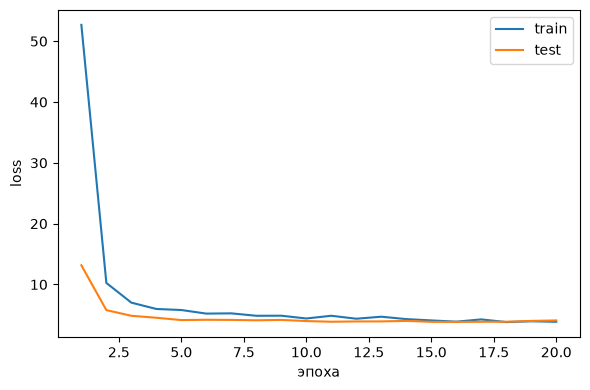

epoch 01  train 52.686  test 13.157
epoch 02  train 10.251  test 5.785
epoch 03  train 7.011  test 4.849
epoch 04  train 5.969  test 4.525
epoch 05  train 5.797  test 4.143
epoch 06  train 5.208  test 4.194
epoch 07  train 5.249  test 4.170
epoch 08  train 4.851  test 4.106
epoch 09  train 4.863  test 4.171
epoch 10  train 4.405  test 3.981
epoch 11  train 4.851  test 3.871
epoch 12  train 4.366  test 3.917
epoch 13  train 4.697  test 3.926
epoch 14  train 4.304  test 4.009
epoch 15  train 4.087  test 3.855
epoch 16  train 3.882  test 3.842
epoch 17  train 4.254  test 3.864
epoch 18  train 3.813  test 3.868
epoch 19  train 3.944  test 4.004
epoch 20  train 3.866  test 4.085


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/var/folders/j4/f4ld9p7s3_d235zfjq14lgww0000gn/T/ipykernel_23021/333760411.py:219: DeprecationWarning:

You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html

/Users/user/Education/CVYandexCamp/venv/lib/python3.12/site-packages/transformers/models/rt_detr/modeling_rt_detr_resnet.py:108: TracerWarning:

Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!

/Users/user/Education/CVYandexCamp/venv/lib/python3.12/site-packages/transformers/integrations/sdpa_attention.py:136: TracerWarning:

Conve

KeyboardInterrupt: 

In [7]:
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import display
from torch.utils.data import DataLoader, Subset
from transformers import RTDetrImageProcessor, RTDetrV2Config, RTDetrV2ForObjectDetection

repo = Path("/Users/user/Education/YandexCamp/CeramicNet/CeramicNet")
data_root = repo.parent
photos = data_root / "Клеймы "
sys.path.insert(0, str(repo))

from dataset import StampDataset, get_collate_fn
from dataset.transforms import Brightness, Compose, Grayscale, HorizontalFlip, VerticalFlip

task = Task.init(
    project_name="CeramicNet",
    task_name="rtdetr_v2_s",
    reuse_last_task_id=False,
    auto_connect_frameworks={"pytorch": False, "matplotlib": True},
)

params = {
    "model_name": "PekingU/rtdetr_v2_r18vd",
    "data_path": str(data_root / "stamps_coco_merged"),
    "negative_ornaments": str(photos / "ornaments_without_copies"),
    "negative_empty": str(photos / "empty"),
    "negative_ratio": 0.2,
    "val_ratio": 0.2,
    "seed": 42,
    "epochs": 20,
    "batch_size": 4,
    "imgsz": 640,
    "lr": 1e-4,
    "lr_backbone": 1e-5,
    "weight_decay": 1e-4,
    "grad_clip": 0.1,
    "hflip_p": 0.5,
    "vflip_p": 0.5,
    "grayscale_p": 0.3,
    "brightness_p": 0.5,
    "num_workers": 0,
    "device": "mps",
    "output_dir": str(repo / "runs" / "rtdetr_v2_s"),
}
task.connect(params)

seed = int(params["seed"])
imgsz = int(params["imgsz"])
epochs = int(params["epochs"])
batch_size = int(params["batch_size"])
num_workers = int(params["num_workers"])
val_ratio = float(params["val_ratio"])
negative_ratio = float(params["negative_ratio"])
root = Path(params["data_path"])
ann_path = root / "annotations" / "instances_default.json"
if not ann_path.is_file():
    raise FileNotFoundError(
        f"В {root} нет annotations/instances_default.json. "
        "Нужны annotations/instances_default.json и images/default."
    )

negative_dirs = [
    path
    for path in (params["negative_ornaments"], params["negative_empty"])
    if str(path).strip()
]
common = dict(
    root_dir=root,
    standard_size=(imgsz, imgsz),
    model="rtdetr",
    negative_dirs=negative_dirs,
    negative_ratio=negative_ratio,
)
source = StampDataset(**common)
order = list(range(len(source)))
random.Random(seed).shuffle(order)
n_test = int(len(order) * val_ratio)
test_index, train_index = order[:n_test], order[n_test:]

train_data = StampDataset(
    **common,
    transform=Compose([
        HorizontalFlip(float(params["hflip_p"])),
        VerticalFlip(float(params["vflip_p"])),
        Grayscale(float(params["grayscale_p"])),
        Brightness(float(params["brightness_p"])),
    ]),
)
test_data = StampDataset(**common)
print("train", len(train_index), "test", len(test_index), "всего", len(source))

requested = str(params["device"])
if requested == "cpu":
    device = torch.device("cpu")
elif requested == "mps" and torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda", int(requested) if requested.isdigit() else 0)
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(device)

config = RTDetrV2Config.from_pretrained(params["model_name"])
config.num_labels = 1
config.id2label = {0: "kleimo"}
config.label2id = {"kleimo": 0}
model = RTDetrV2ForObjectDetection.from_pretrained(
    params["model_name"],
    config=config,
    ignore_mismatched_sizes=True,
).to(device)
processor = RTDetrImageProcessor.from_pretrained(params["model_name"])

collate_fn = get_collate_fn("rtdetr")
torch.manual_seed(seed)
generator = torch.Generator()
generator.manual_seed(seed)
train_loader = DataLoader(
    Subset(train_data, train_index),
    batch_size=batch_size,
    shuffle=True,
    generator=generator,
    num_workers=num_workers,
    collate_fn=collate_fn,
)
test_loader = DataLoader(
    Subset(test_data, test_index),
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=collate_fn,
)

backbone_params = list(model.model.backbone.parameters())
backbone_ids = {id(param) for param in backbone_params}
other_params = [param for param in model.parameters() if id(param) not in backbone_ids]
optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": float(params["lr_backbone"])},
        {"params": other_params, "lr": float(params["lr"])},
    ],
    weight_decay=float(params["weight_decay"]),
)
grad_clip = float(params["grad_clip"])


def run_epoch(loader, train):
    model.train(train)
    total, count = 0.0, 0
    for images, labels in loader:
        images = images.to(device)
        labels = [{key: value.to(device) for key, value in item.items()} for item in labels]
        with torch.set_grad_enabled(train):
            loss = model(pixel_values=images, labels=labels).loss
            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()
        total += float(loss.detach()) * images.shape[0]
        count += images.shape[0]
    return total / count


save_dir = Path(params["output_dir"])
save_dir.mkdir(parents=True, exist_ok=True)
logger = task.get_logger()
best_loss = None
best_state = None
train_losses, test_losses = [], []
fig, ax = plt.subplots(figsize=(6, 4))
chart = display(fig, display_id=True)
for epoch in range(1, epochs + 1):
    train_loss = run_epoch(train_loader, train=True)
    test_loss = run_epoch(test_loader, train=False)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    logger.report_scalar("loss", "train", train_loss, epoch)
    logger.report_scalar("loss", "test", test_loss, epoch)
    print(f"epoch {epoch:02d}  train {train_loss:.3f}  test {test_loss:.3f}")
    if best_loss is None or test_loss < best_loss:
        best_loss = test_loss
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    ax.clear()
    ax.plot(range(1, epoch + 1), train_losses, label="train")
    ax.plot(range(1, epoch + 1), test_losses, label="test")
    ax.set_xlabel("эпоха")
    ax.set_ylabel("loss")
    ax.legend()
    fig.tight_layout()
    fig.savefig(save_dir / "loss.png")
    chart.update(fig)
plt.close(fig)

model.load_state_dict(best_state)
model.eval()
model.save_pretrained(save_dir)
processor.save_pretrained(save_dir)
logger.report_single_value("best_test_loss", best_loss)


class _OnnxDet(torch.nn.Module):
    def __init__(self, detector):
        super().__init__()
        self.detector = detector

    def forward(self, pixel_values):
        out = self.detector(pixel_values=pixel_values)
        return out.logits, out.pred_boxes


onnx_path = save_dir / "rtdetr_v2_s.onnx"
torch.onnx.export(
    _OnnxDet(model).cpu().eval(),
    (torch.zeros(1, 3, imgsz, imgsz),),
    onnx_path,
    input_names=["pixel_values"],
    output_names=["logits", "pred_boxes"],
    dynamo=False,
)
model.to(device)
task.upload_artifact("onnx", artifact_object=str(onnx_path))
task.upload_artifact("loss_plot", artifact_object=str(save_dir / "loss.png"))
task.close()
print("сохранено", save_dir, "test loss", round(best_loss, 3))

stamps/Т-12-Р4-771_1.png gt 1 pred 1


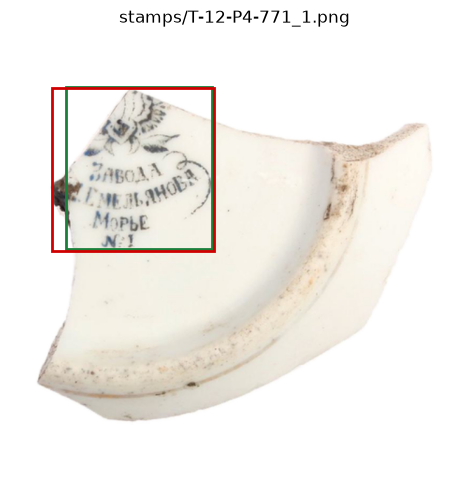

stamps/КБ-2014-Р4-410_7.png gt 1 pred 1


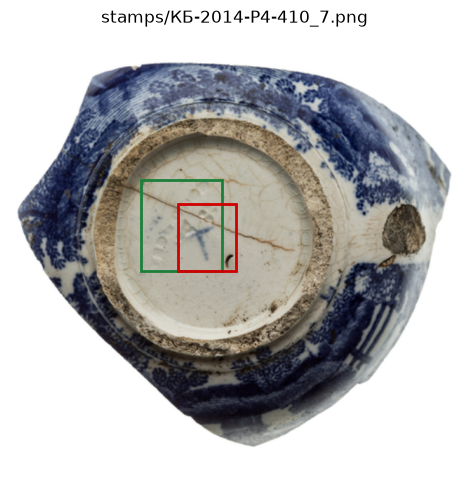

stamps/Т-12-Р3-1028_30.png gt 1 pred 1


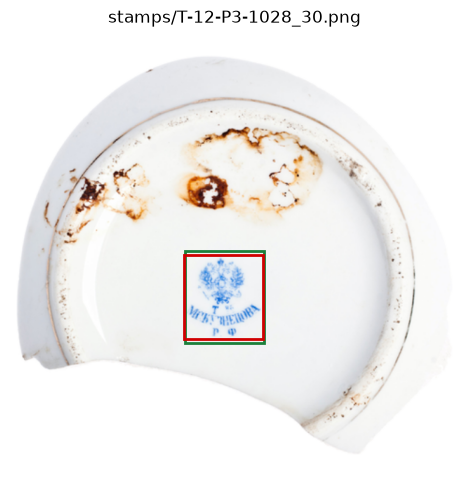

stamps/КБ-2014-Р1-0257_6.png gt 1 pred 2


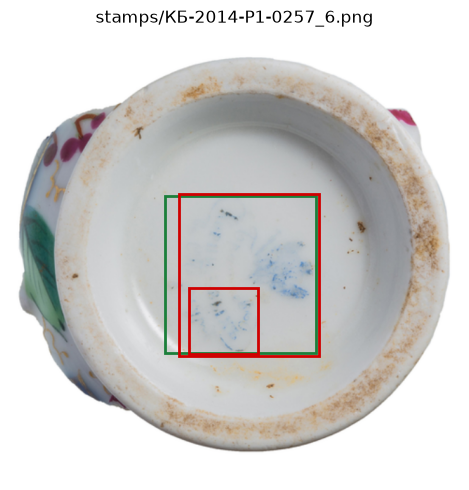

stamps/КБ-2014-Р5-0419_3.png gt 1 pred 1


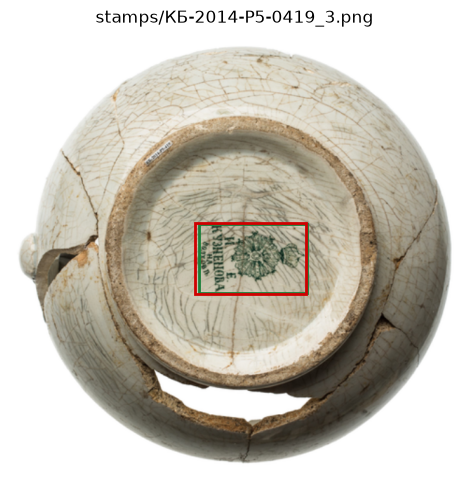

stamps/КБ-2014-Р2-0596_3.png gt 1 pred 2


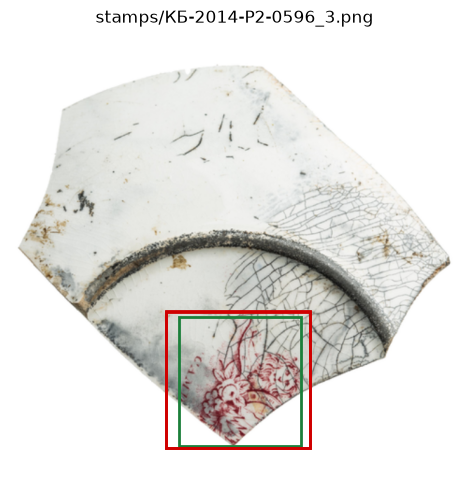

stamps/КБ-2014-Р2-0241_5.png gt 1 pred 1


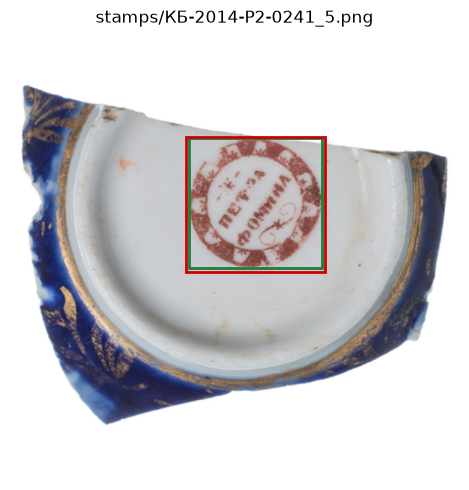

stamps/Нц-46-335_2.png gt 1 pred 1


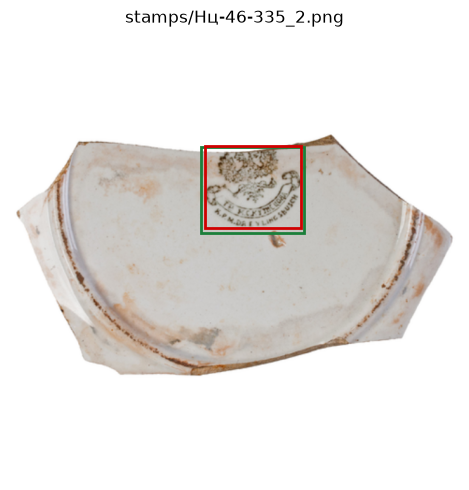

stamps/Т-12-Р3-1027_4.png gt 1 pred 1


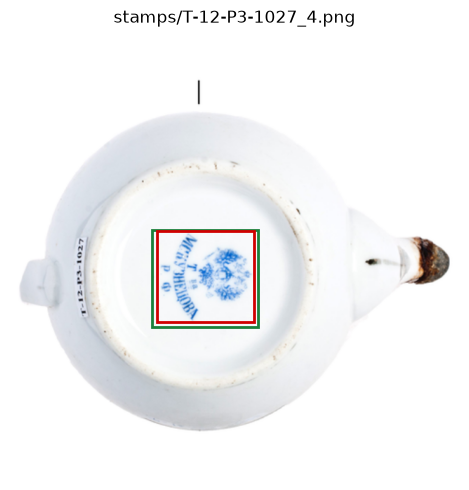

stamps/Нейш3А-2018-5236_2.png gt 1 pred 1


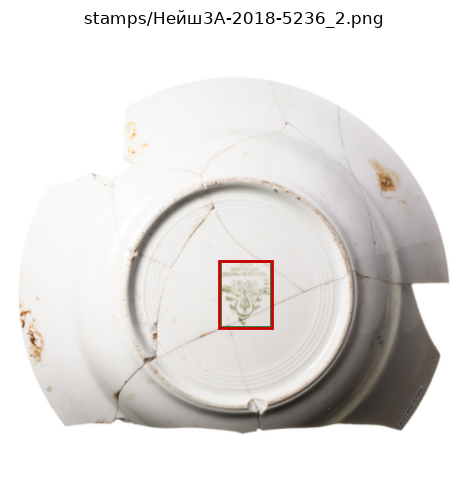

stamps/Нейш3А-2018-5707_11.png gt 1 pred 1


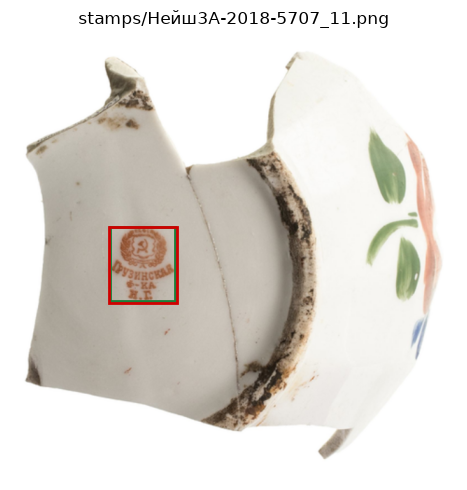

stamps/Т-12-Р3-378_11.png gt 1 pred 1


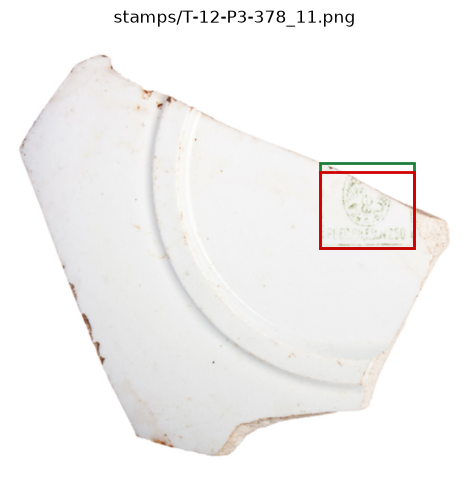

stamps/Нейш3А-2018-4584_7.png gt 1 pred 1


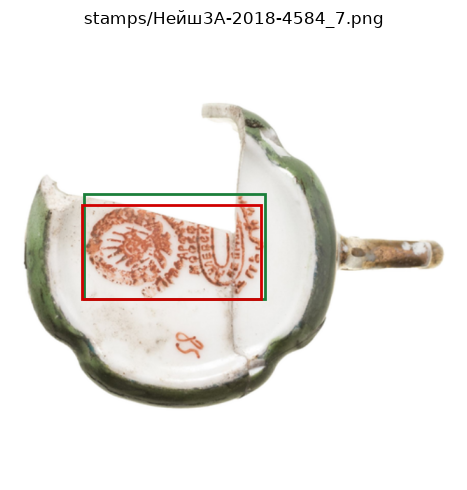

stamps/Т-12-Р4-1174_3.png gt 1 pred 1


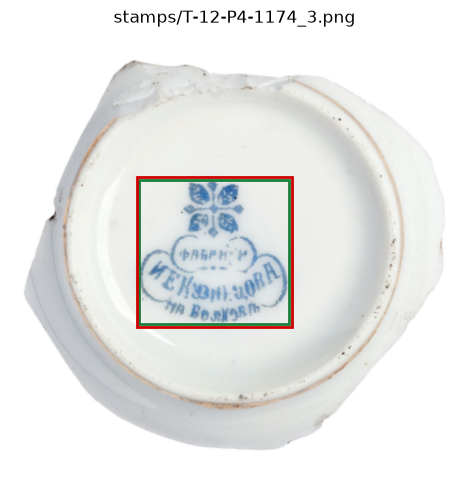

stamps/Нц-46-272_5.png gt 1 pred 1


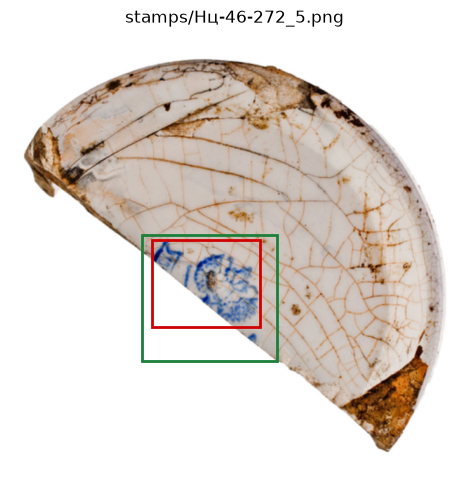

stamps/БП12-Г01-5844_1.png gt 1 pred 1


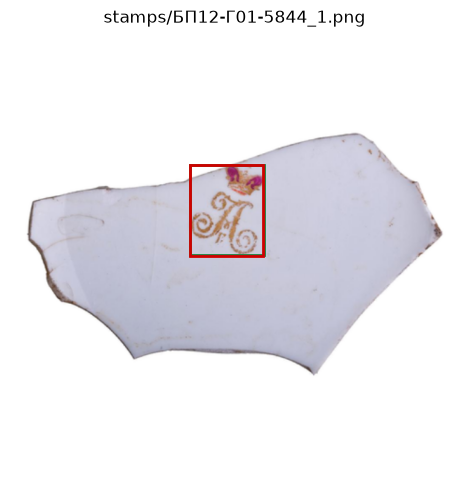

stamps/Нейш3А-2018-4913_4.png gt 1 pred 1


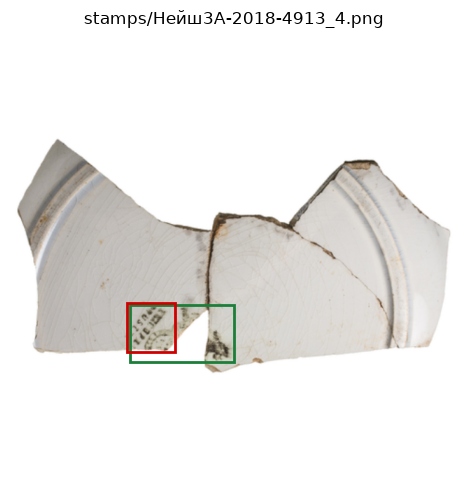

stamps/Т-12-Р4-041_2.png gt 1 pred 1


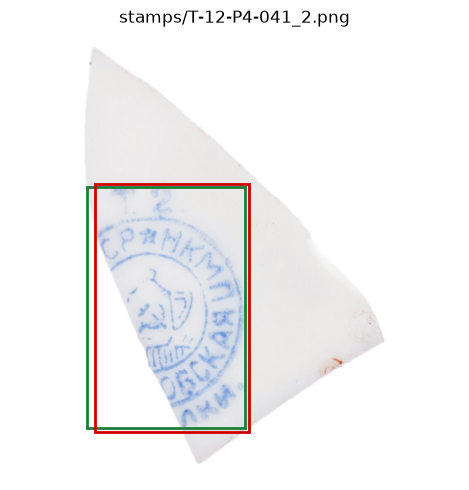

stamps/БП12-Г01-1082_6.png gt 1 pred 1


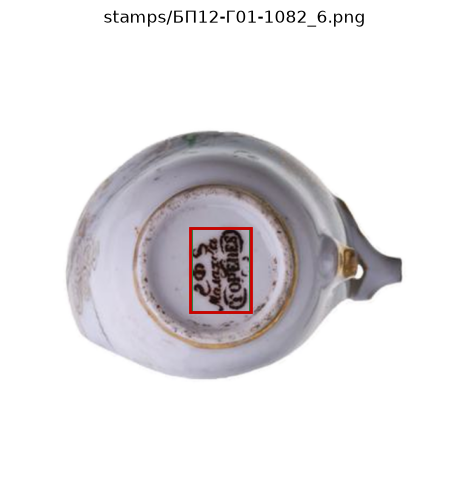

stamps/КБ-2014-Р2-0703_12.png gt 1 pred 1


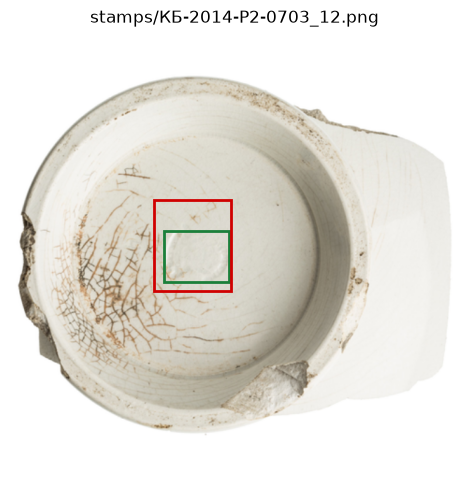

stamps/Т-12-Р4-246_4.png gt 1 pred 1


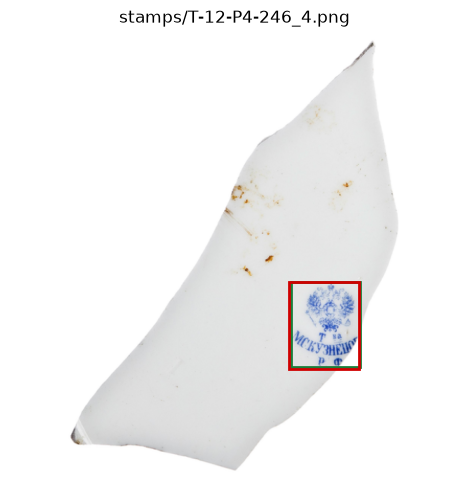

stamps/Нейш3А-2018-6344_14.png gt 1 pred 1


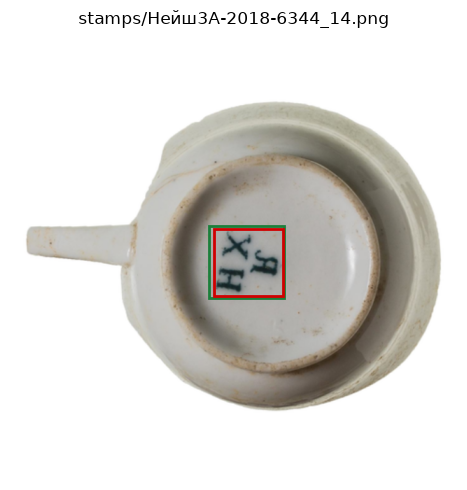

stamps/КБ-2014-Р2-0433_7.png gt 1 pred 1


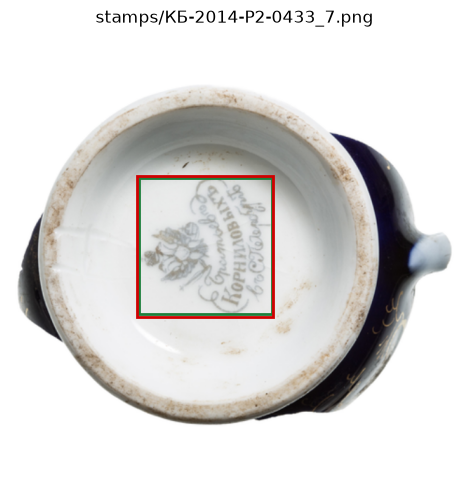

stamps/Нейш3А-2018-4745_5.png gt 1 pred 1


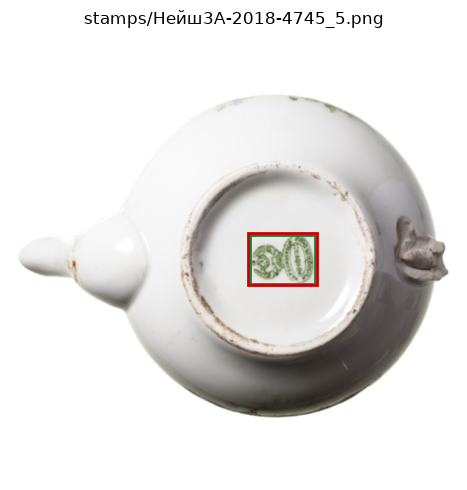

stamps/Т-12-Р3-2359_5.png gt 1 pred 1


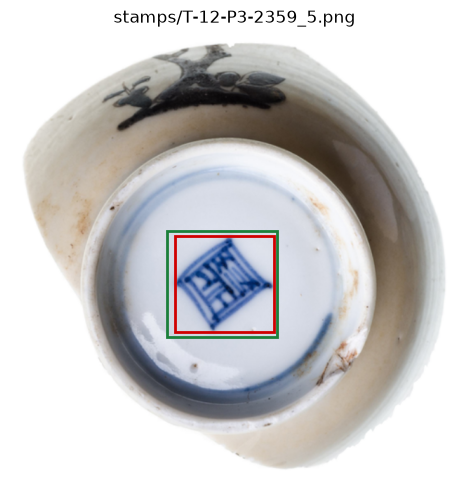

stamps/Т-12-Р3-974_2.png gt 1 pred 1


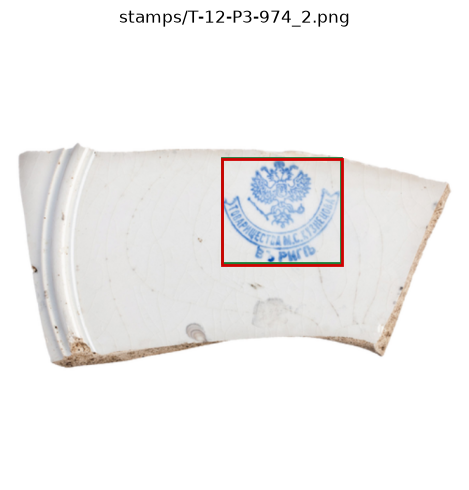

stamps/КБ-2014-Р3-0033_2.png gt 1 pred 1


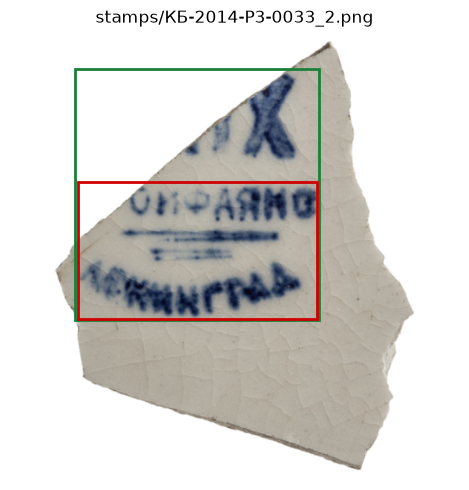

stamps/ВО-1л58-2017-0427_9.png gt 1 pred 1


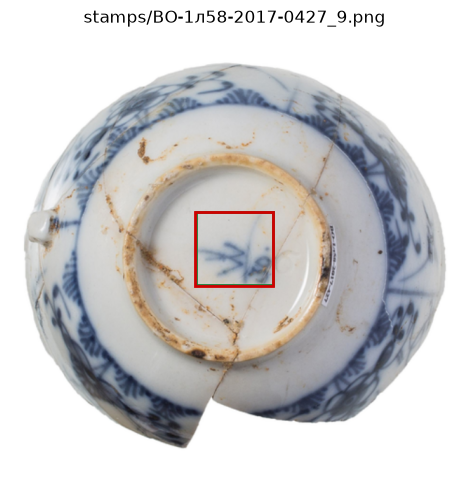

stamps/БП12-Г02-3659_5.png gt 1 pred 1


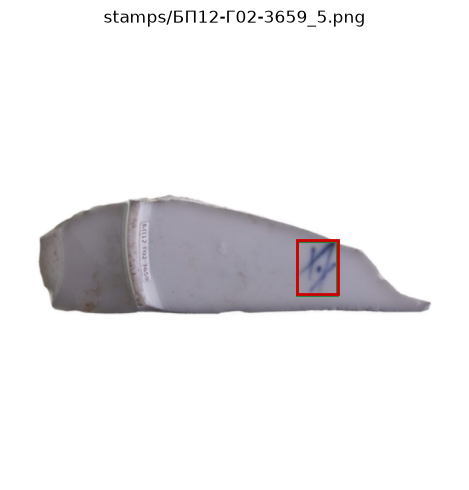

stamps/Т-12-Р4-1262_3.png gt 1 pred 1


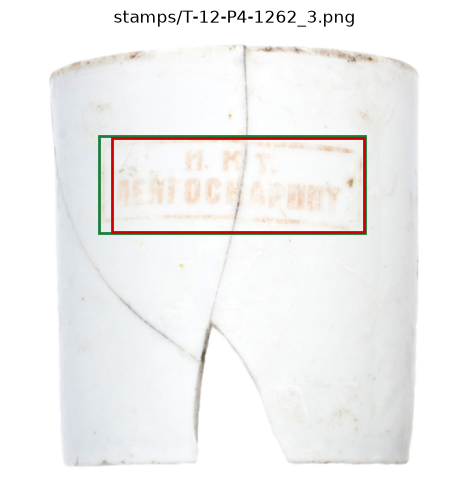

stamps/Т-12-Р4-117_7.png gt 1 pred 1


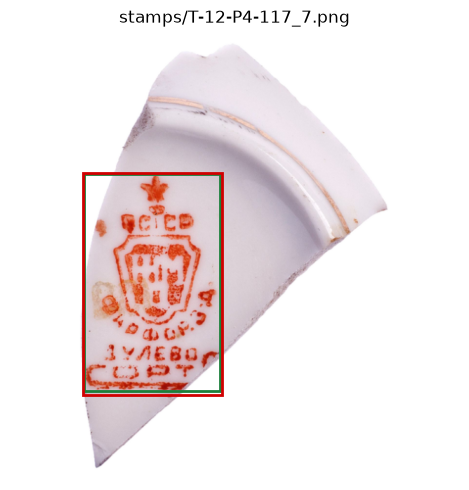

stamps/КБ-2014-Р2-0360_7.png gt 1 pred 1


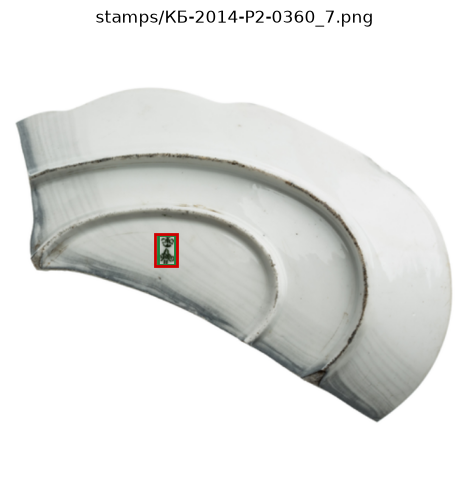

stamps/КБ-2014-Р4-424_5.png gt 1 pred 1


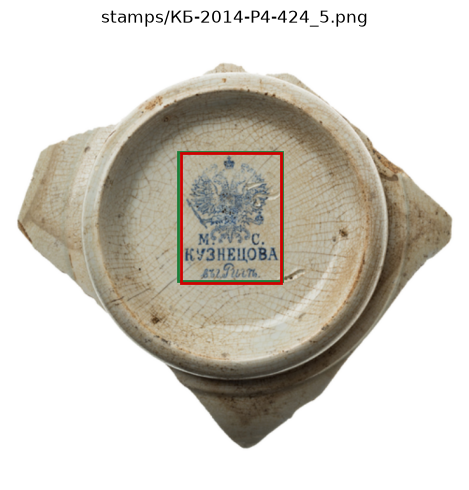

stamps/Т-12-Р3-961_3.png gt 1 pred 1


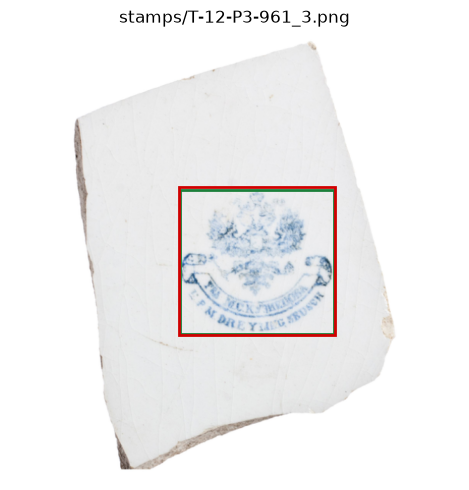

stamps/КБ-2014-Р5-0401_5.png gt 1 pred 1


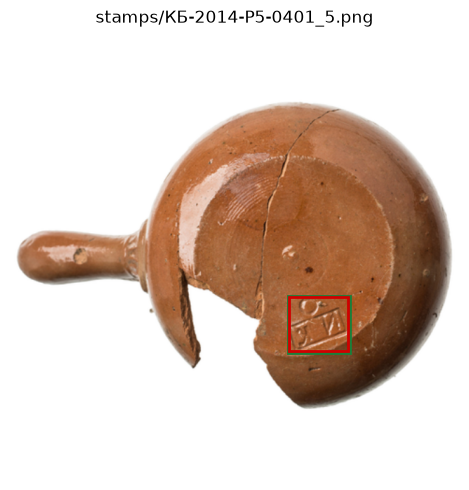

stamps/Кроп-2013-Тр1-019_2.png gt 1 pred 1


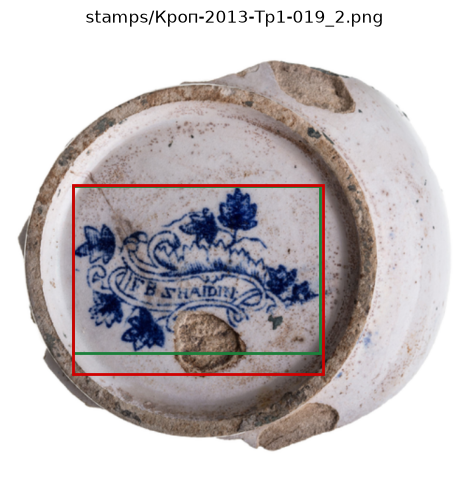

stamps/КБ-2014-Р5-0097_1.png gt 1 pred 1


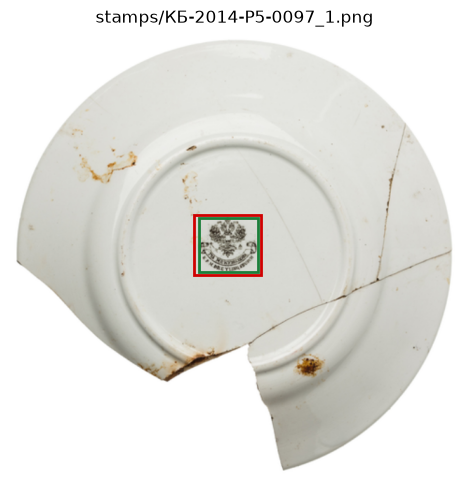

stamps/Т-12-Р4-1220_5.png gt 1 pred 1


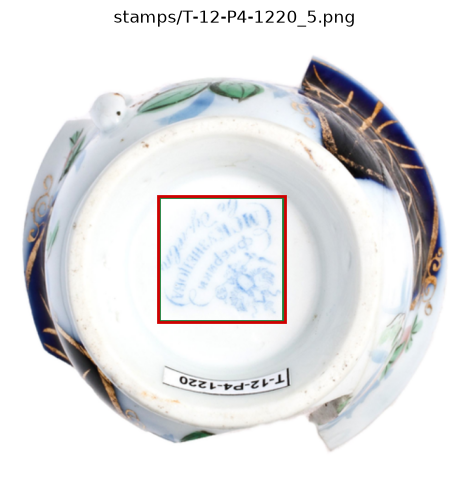

stamps/Т-12-Р2-618_2.png gt 1 pred 1


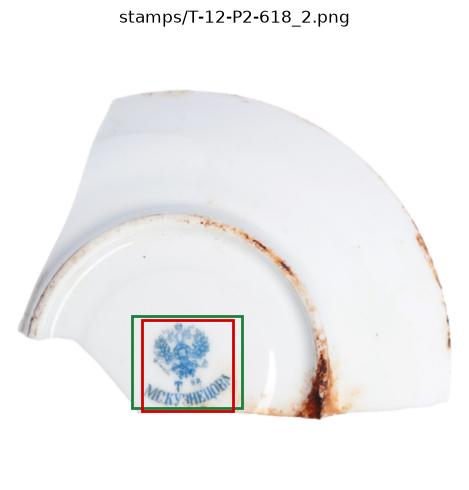

stamps/КБ-2014-Р5-0093_1.png gt 1 pred 1


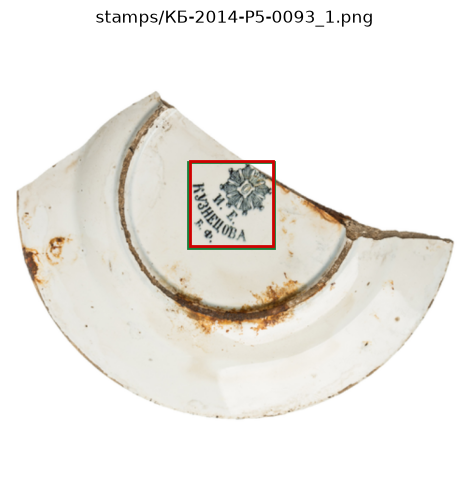

stamps/КБ-2014-Р5-0071_28.png gt 1 pred 1


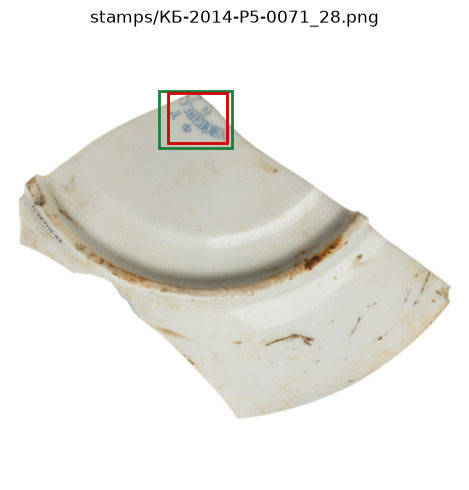

stamps/КБ-2014-Р2-0670_2.png gt 1 pred 1


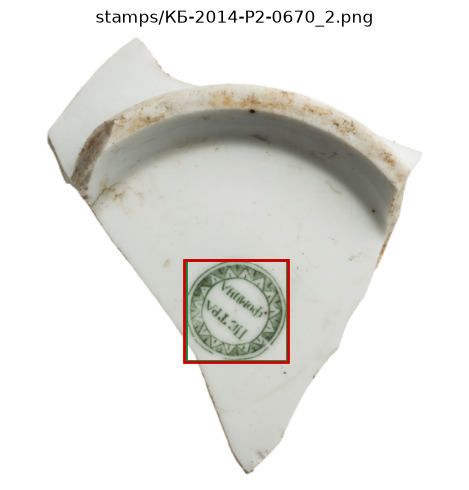

stamps/Нейш3А-2018-4979_5.png gt 1 pred 1


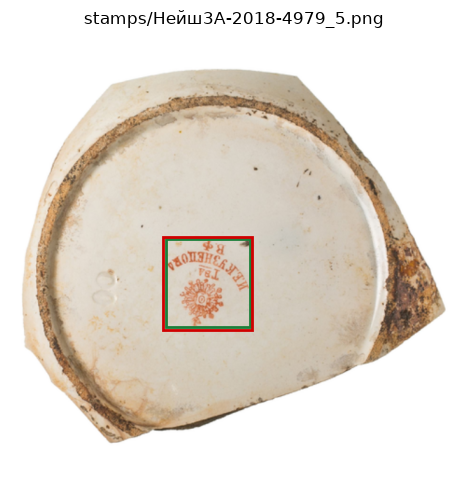

stamps/КБ-2014-Р1-1100_5.png gt 1 pred 1


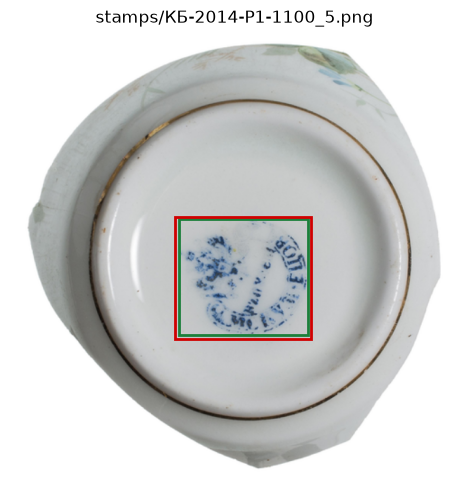

stamps/Т-12-Р4-500_1.png gt 1 pred 1


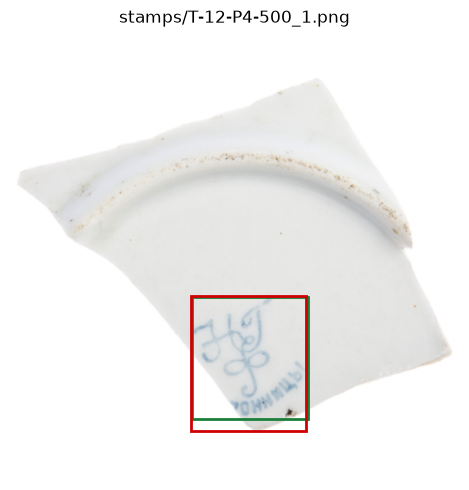

stamps/КБ-2014-Р5-0422_5.png gt 1 pred 1


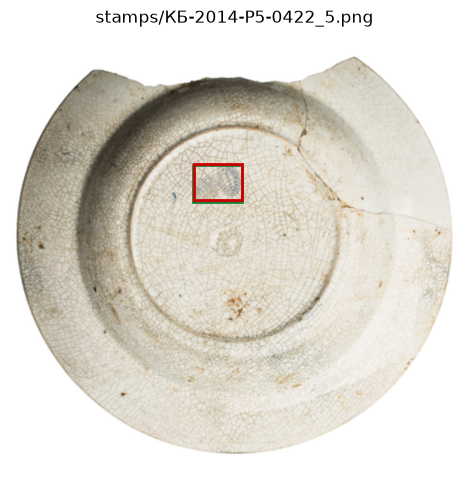

stamps/Нц-30-753_2.png gt 1 pred 1


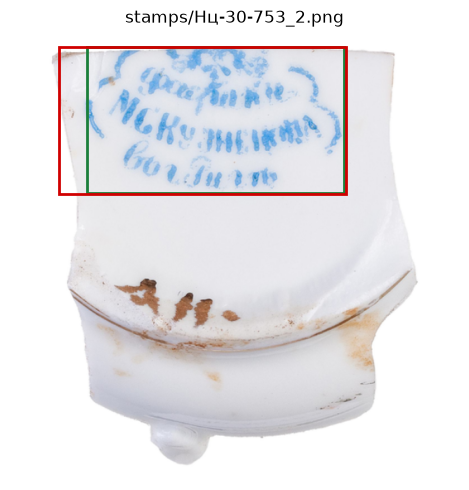

ornaments_without_copies/БП12-Т02-7987_6.png gt 0 pred 0


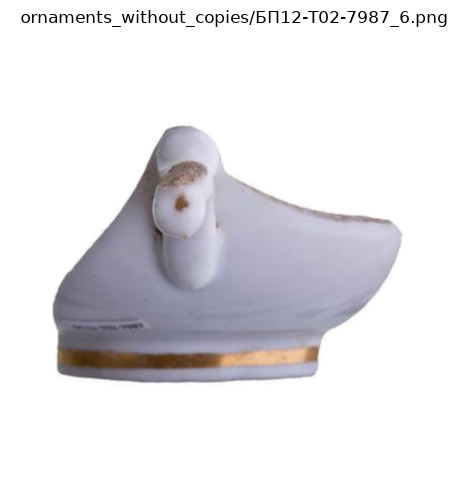

In [12]:
from matplotlib.patches import Rectangle


def cxcywh_to_xyxy(boxes, size):
    if len(boxes) == 0:
        return boxes.new_zeros((0, 4))
    cx, cy, width, height = boxes.unbind(-1)
    return torch.stack(
        (
            (cx - width / 2) * size,
            (cy - height / 2) * size,
            (cx + width / 2) * size,
            (cy + height / 2) * size,
        ),
        dim=-1,
    )


def draw(ax, picture, boxes, color, title):
    ax.imshow(picture)
    for box in boxes:
        x1, y1, x2, y2 = [float(value) for value in box]
        ax.add_patch(
            Rectangle((x1, y1), max(x2 - x1, 1), max(y2 - y1, 1), fill=False, edgecolor=color, linewidth=2)
        )
    ax.set_title(title)
    ax.axis("off")


model.eval()
shown = [index for index in test_index if len(test_data.items[index]["boxes"])]
empty = [index for index in test_index if len(test_data.items[index]["boxes"]) == 0]
if empty:
    shown.append(empty[0])

for index in shown:
    image, target = test_data[index]
    with torch.no_grad():
        outputs = model(pixel_values=image.unsqueeze(0).to(device))
    outputs.logits = outputs.logits.cpu()
    outputs.pred_boxes = outputs.pred_boxes.cpu()
    pred = processor.post_process_object_detection(
        outputs,
        threshold=0.4,
        target_sizes=[(imgsz, imgsz)],
    )[0]
    picture = image.permute(1, 2, 0).numpy()
    gt = cxcywh_to_xyxy(target["boxes"], imgsz)
    name = test_data.items[index]["file_name"]
    print(name, "gt", int(len(gt)), "pred", int(len(pred["boxes"])))
    fig, ax = plt.subplots(figsize=(5, 5))
    draw(ax, picture, gt, "#1b7f3a", "")
    draw(ax, picture, pred["boxes"], "#d00000", name)
    plt.tight_layout()
    display(fig)
    plt.close(fig)